No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
No normalization for NumAmideBonds. Feature removed!
No normalization for NumAtomStereoCenters. Feature removed!
No normalization for NumBridgeheadAtoms. Feature removed!
No normalization for NumHeterocycles. Feature removed!
No normalization for NumSpiroAtoms. Feature removed!
No normalization for NumUnspecifiedAtomStereoCenters. Feature removed!
No normalization for Phi. Feature removed!
Skipped loading material featurizer, missing a dependency. No module named 'ase'
/home/sachinkukkar/miniforge3/envs/open_pom/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading some PyTorch models, missing a dependency. No module

Using model 6 (valid AUROC 0.885)
numbers per molecule: GNN 256 | fingerprint 2048


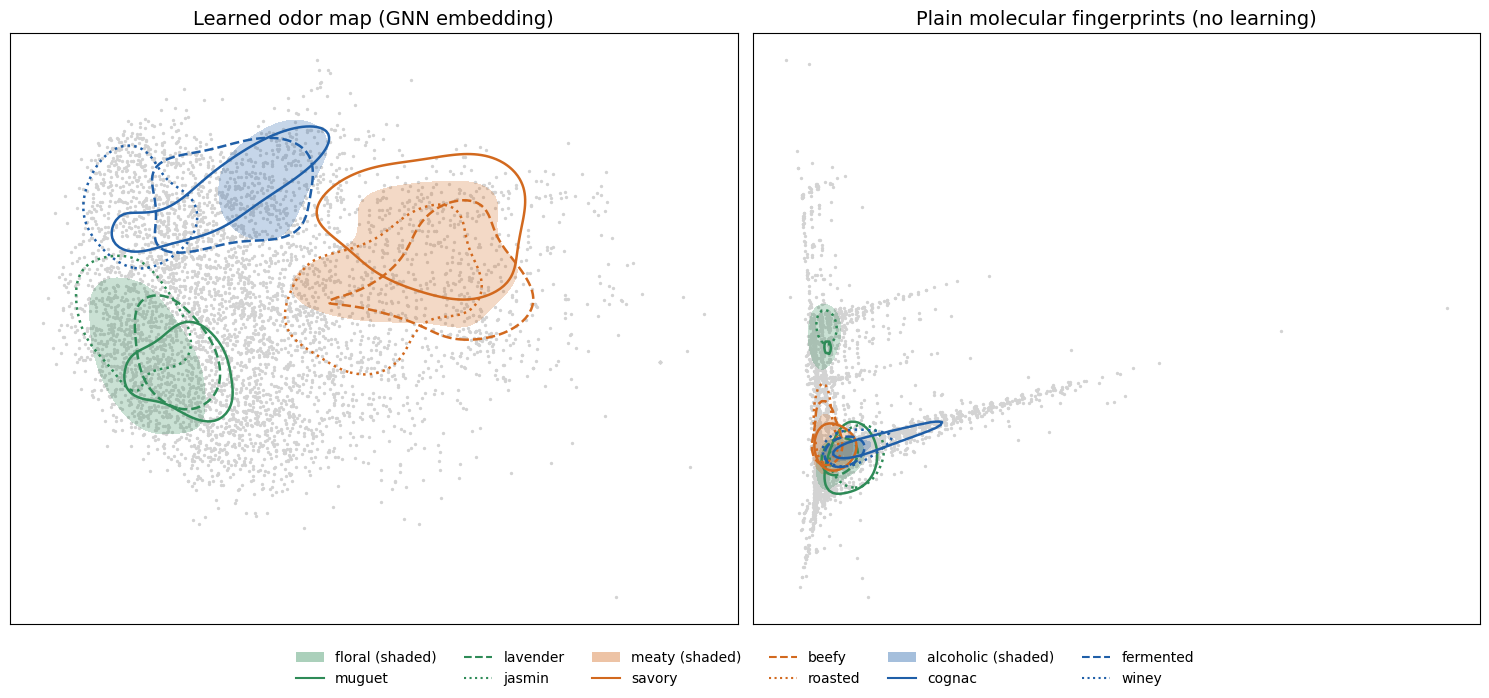

Saved to /home/sachinkukkar/ai-nose/figures/odor_map.png


In [1]:
import os, json, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from openpom.feat.graph_featurizer import GraphConvConstants
from openpom.utils.data_utils import get_class_imbalance_ratio
from openpom.models.mpnn_pom import MPNNPOMModel
warnings.filterwarnings("ignore", category=FutureWarning)

DATA = os.path.expanduser("~/ai-nose/data")
ENS  = os.path.expanduser("~/ai-nose/models/ensemble")
FIG  = os.path.expanduser("~/ai-nose/figures"); os.makedirs(FIG, exist_ok=True)
full  = dc.data.DiskDataset(f"{DATA}/all")
train = dc.data.DiskDataset(f"{DATA}/train")
TASKS = list(full.tasks)

def make_model(model_dir):
    lr = dc.models.optimizers.ExponentialDecay(initial_rate=0.001, decay_rate=0.5, decay_steps=32*20, staircase=True)
    return MPNNPOMModel(
        n_tasks=len(TASKS), batch_size=128, learning_rate=lr,
        class_imbalance_ratio=get_class_imbalance_ratio(train), loss_aggr_type="sum",
        node_out_feats=100, edge_hidden_feats=75, edge_out_feats=100,
        num_step_message_passing=5, mpnn_residual=True, message_aggregator_type="sum",
        mode="classification", number_atom_features=GraphConvConstants.ATOM_FDIM,
        number_bond_features=GraphConvConstants.BOND_FDIM, n_classes=1,
        readout_type="set2set", num_step_set2set=3, num_layer_set2set=2,
        ffn_hidden_list=[392, 392], ffn_embeddings=256, ffn_activation="relu",
        ffn_dropout_p=0.12, ffn_dropout_at_input_no_act=False, weight_decay=1e-5,
        self_loop=False, optimizer_name="adam", log_frequency=32,
        model_dir=model_dir, device_name="cuda")

# 1. Pick the single model with the best VALIDATION score
val = {i: json.load(open(f"{ENS}/model_{i}/done.json"))["valid_auroc"] for i in range(10)}
best_i = max(val, key=val.get)
print(f"Using model {best_i} (valid AUROC {val[best_i]:.3f})")
model = make_model(f"{ENS}/model_{best_i}")
model.restore(model_dir=f"{ENS}/model_{best_i}/best")

# 2. Two ways to describe each molecule: the learned embedding and a plain fingerprint
emb = np.asarray(model.predict_embedding(full)).reshape(len(full), -1)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = np.array([gen.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in full.ids], dtype=np.float32)
print("numbers per molecule: GNN", emb.shape[1], "| fingerprint", fps.shape[1])
xy_gnn = PCA(n_components=2).fit_transform(emb)
xy_fp  = PCA(n_components=2).fit_transform(fps)

# 3. Shaded area = a broad smell family; lines = more specific smells inside that family
FAMILIES = [("floral",    "#2E8B57", ["muguet", "lavender", "jasmin"]),
            ("meaty",     "#D2691E", ["savory", "beefy", "roasted"]),
            ("alcoholic", "#1F5FA8", ["cognac", "fermented", "winey"])]
STYLES = ["-", "--", ":"]

def density(xy, mask, grid):
    pts = xy[mask]
    kde = gaussian_kde(pts.T)
    Z = kde(np.vstack([grid[0].ravel(), grid[1].ravel()])).reshape(grid[0].shape)
    level = np.percentile(kde(pts.T), 50)   # outline the densest half of these molecules
    return Z, level

def odor_map(ax, xy, title):
    pad = 0.05 * (xy.max(0) - xy.min(0))
    lo, hi = xy.min(0) - pad, xy.max(0) + pad
    grid = np.meshgrid(np.linspace(lo[0], hi[0], 200), np.linspace(lo[1], hi[1], 200))
    ax.scatter(xy[:, 0], xy[:, 1], s=2, c="lightgray")
    handles = []
    for fam, color, subs in FAMILIES:
        Z, lev = density(xy, full.y[:, TASKS.index(fam)] == 1, grid)
        ax.contourf(*grid, Z, levels=[lev, Z.max()], colors=[color], alpha=0.25)
        handles.append(Patch(facecolor=color, alpha=0.4, label=f"{fam} (shaded)"))
        for sub, ls in zip(subs, STYLES):
            Z, lev = density(xy, full.y[:, TASKS.index(sub)] == 1, grid)
            ax.contour(*grid, Z, levels=[lev], colors=[color], linestyles=ls, linewidths=1.8)
            handles.append(Line2D([0], [0], color=color, linestyle=ls, label=sub))
    ax.set_title(title, fontsize=14); ax.set_xticks([]); ax.set_yticks([])
    return handles

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
handles = odor_map(axes[0], xy_gnn, "Learned odor map (GNN embedding)")
odor_map(axes[1], xy_fp, "Plain molecular fingerprints (no learning)")
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(f"{FIG}/odor_map.png", dpi=150)
plt.show()
print("Saved to", f"{FIG}/odor_map.png")

In [2]:
import glob, pandas as pd
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import roc_auc_score

test = dc.data.DiskDataset(f"{DATA}/test")

def mean_auroc(y_true, y_prob):
    s = [roc_auc_score(y_true[:, j], y_prob[:, j]) for j in range(y_true.shape[1]) if 0 < y_true[:, j].sum() < len(y_true)]
    return float(np.mean(s))

def knn_probs(knn, X):
    return np.column_stack([p[:, 1] if p.shape[1] == 2 else np.zeros(len(X)) for p in knn.predict_proba(X)])

def bits(smiles):
    return np.array([gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles]).astype(bool)

# Each molecule described two ways: learned embedding vs. fingerprint bits
emb_tr = np.asarray(model.predict_embedding(train)).reshape(len(train), -1)
emb_te = np.asarray(model.predict_embedding(test)).reshape(len(test), -1)
fp_tr, fp_te = bits(train.ids), bits(test.ids)

# Predict each test molecule's smells from its 20 nearest training molecules
knn_g = KNeighborsClassifier(n_neighbors=20, metric="cosine",  weights="distance").fit(emb_tr, train.y)
knn_f = KNeighborsClassifier(n_neighbors=20, metric="jaccard", weights="distance").fit(fp_tr, train.y)
print(f"kNN using the GNN odor map: test AUROC {mean_auroc(test.y, knn_probs(knn_g, emb_te)):.3f}   (paper: 0.818)")
print(f"kNN using fingerprints:     test AUROC {mean_auroc(test.y, knn_probs(knn_f, fp_te)):.3f}   (paper: 0.782)")

# A look at the actual neighbours of one test molecule
path = glob.glob(os.path.expanduser("~/openpom/**/*4983*.csv"), recursive=True)[0]
df = pd.read_csv(path)
desc = dict(zip(df["nonStereoSMILES"], df["descriptors"]))
nn_g = NearestNeighbors(n_neighbors=5, metric="cosine").fit(emb_tr)
nn_f = NearestNeighbors(n_neighbors=5, metric="jaccard").fit(fp_tr)

def show_neighbours(i):
    s = test.ids[i]
    print(f"\nTEST molecule {s}\n  real smells: {desc[s].replace(';', ', ')}")
    for name, nn, X in [("GNN odor map", nn_g, emb_te), ("fingerprints", nn_f, fp_te)]:
        print(f"  5 nearest training molecules by {name}:")
        for j in nn.kneighbors(X[i:i+1], return_distance=False)[0]:
            t = train.ids[j]
            print(f"    {t:32s} {desc[t].replace(';', ', ')}")

show_neighbours(0)

kNN using the GNN odor map: test AUROC 0.818   (paper: 0.818)
kNN using fingerprints:     test AUROC 0.794   (paper: 0.782)

TEST molecule CCCC=O
  real smells: fruity, chocolate, pungent, cocoa, malty, green, musty
  5 nearest training molecules by GNN odor map:
    CCC=O                            brandy, earthy, nutty, alcoholic, pungent, winey, cocoa, cognac, meaty, grape, green, ethereal
    CCCCC=O                          berry, fruity, chocolate, nutty, pungent, fermented
    CCC(C)C=O                        fresh, phenolic, burnt, fatty, chocolate, nutty, fruity, alcoholic, malty, cocoa, coffee, green, musty, fermented
    CC=O                             fresh, fruity, nutty, alcoholic, pungent, aldehydic, musty, ethereal
    C=CCOCC                          sharp, ethereal
  5 nearest training molecules by fingerprints:
    CCCCC=O                          berry, fruity, chocolate, nutty, pungent, fermented
    CCCCCC=O                         fresh, woody, fatty, grassy, fr